# Day 2-01｜モデルの出力を読む：YOLO による物体検出

[Colab で開く](https://colab.research.google.com/github/henry753951/basketball-hackathon-course/blob/main/day2/d2_01_yolo26_detection_ja.ipynb)

[English](d2_01_yolo26_detection_en.ipynb) | [Japanese](d2_01_yolo26_detection_ja.ipynb) | [Traditional Chinese](d2_01_yolo26_detection.ipynb)


> Day 1 のアノテーションを引き継ぎ、アップロードや矩形の作成は繰り返さない。この単元ではモデルの出力を一つずつ確認する。  
> ニューラルネットワークの詳細をすべて知る必要はない。まず入力、出力、失敗例を理解する。

## 学習目標

- 学習済みの YOLO の重みを読み込み、動画の 1 フレームを推論する。
- `class_name`、`confidence`、`bbox_xyxy` の意味を読む。
- 短い検出確認動画を出力し、矩形の時間変化を観察する。
- 信頼度のしきい値が見落としや誤検出に与える影響を説明する。

## 用語

- **推論（Inference）**：学習済みモデルに新しい画像を入力し、予測を得ること。
- **信頼度（Confidence）**：モデルが予測に付けるスコア。正しさを保証する値ではない。
- **`xyxy`**：`[左, 上, 右, 下]` の順に並べた四つの画素座標。
- **しきい値（Threshold）**：指定した信頼度を上回る予測だけを残す基準値。


## 実行環境の確認

- Colab では **GPU** ランタイムを選ぶ。本教材の Ultralytics／PyTorch の設定では TPU を直接使用しない。
- CPU でも実行できるが、推論や動画の出力に時間がかかる。最初は `MAX_FRAMES` を小さくして処理を確認する。
- 実行前に各セルの目的を読み、出力が想定どおりか確認する。エラーが出ないことだけで正しいと判断しない。


## 演習の流れ：Day 1 からの続き

1. 教材の学習済み重みを使い、Roboflow でのアップロードとアノテーションは繰り返さない。
2. まず 1 フレームを見て、検出結果の各項目を読む。
3. 画像の矩形と DataFrame の `bbox_xyxy` を照合する。
4. 短い動画を処理し、見落とし、重複矩形、信頼度の変動を確認する。
5. Day 3 につながる問いを考える。隣接フレームの同じ選手に、どうすれば同じ ID を付けられるだろうか。


In [1]:
import os
os.environ["BASKETBALL_COURSE_LANGUAGE"] = "ja"

# 教材フォルダを探し、必要なら取得して共通の環境設定を読み込みます。
# まず初期設定で実行し、出力を確認してから一度に一つのパラメータを変えます。
from pathlib import Path
import subprocess
import sys

DRIVE_MOUNTED = False
if "google.colab" in sys.modules:
    from google.colab import drive

    try:
        drive.mount("/content/drive")
        DRIVE_MOUNTED = True
    except NotImplementedError:
        print("この Colab ランタイムでは Drive をマウントできないため、ローカルの /content を使います。")

COURSE_ROOT_HINT = (
    Path("/content/drive/MyDrive/basketball_hackathon/course")
    if DRIVE_MOUNTED
    else next(
        (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
         if (p / "src" / "course_setup.py").exists()),
        Path("/content/basketball_hackathon/course"),
    )
)
if not (COURSE_ROOT_HINT / "src" / "course_setup.py").exists() and "google.colab" in sys.modules:
    COURSE_ROOT_HINT.parent.mkdir(parents=True, exist_ok=True)
    subprocess.run([
        "git", "clone", "--depth", "1", "https://github.com/henry753951/basketball-hackathon-course.git", str(COURSE_ROOT_HINT)
    ], check=True)
if str(COURSE_ROOT_HINT) not in sys.path:
    sys.path.insert(0, str(COURSE_ROOT_HINT))

from src.course_setup import bootstrap_course_repo  # noqa: E402

COURSE_ROOT = bootstrap_course_repo(COURSE_ROOT_HINT, mount_drive=False)


教材ルート： /Users/henry753951/Developer/sandbox/basketball-hackathon-course
素材フォルダ： /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets
共通モジュール： /Users/henry753951/Developer/sandbox/basketball-hackathon-course/src


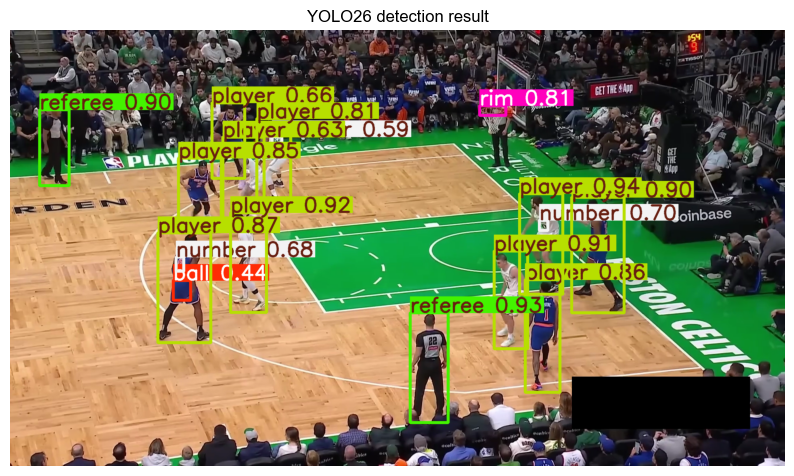

video: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/raw/reference_videos/boston-celtics-new-york-knicks-game-1-q1-01.54-01.48.mp4
model: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/models/detectors/yolo26n_basketball_player_best.pt
detections: 17
saved: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d2_01_yolo26_detection_frame.png


,frame_index,class_id,class_name,confidence,bbox_xyxy,track_id
0,15,3,player,0.936312,"[1262.3990478515625, 405.5212707519531, 1369.7...",None
1,15,8,referee,0.926773,"[991.1038818359375, 700.3985595703125, 1085.72...",None
2,15,3,player,0.922809,"[546.8359375, 452.7620849609375, 635.623779296...",None
3,15,3,player,0.910854,"[1199.2083740234375, 547.0396118164062, 1282.0...",None
4,15,3,player,0.898455,"[1391.52490234375, 414.43505859375, 1521.84143...",None


In [2]:
# 演習の次の処理を実行します。
# まず初期設定で実行し、出力を確認してから一度に一つのパラメータを変えます。
import cv2
import pandas as pd
from ultralytics import YOLO

from src.cv_utils import save_image_rgb, show_image
from src.video_utils import display_video_in_notebook
from src.yolo_utils import detections_from_result, write_detection_preview_video

video_candidates = sorted((COURSE_ROOT / "assets" / "raw" / "reference_videos").glob("*.mp4"))
if not video_candidates:
    raise FileNotFoundError("参照動画がありません。assets/raw/reference_videos/ に mp4 を 1 本以上配置してください。")

VIDEO_PATH = video_candidates[0]
MODEL_PATH = COURSE_ROOT / "assets" / "models" / "detectors" / "yolo26n_basketball_player_best.pt"
FRAME_INDEX = 15

cap = cv2.VideoCapture(str(VIDEO_PATH))
if not cap.isOpened():
    raise FileNotFoundError(VIDEO_PATH)
cap.set(cv2.CAP_PROP_POS_FRAMES, FRAME_INDEX)
ok, frame_bgr = cap.read()
cap.release()
if not ok:
    raise RuntimeError(f"フレーム {FRAME_INDEX} を読めません：{VIDEO_PATH}")
frame = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

model = YOLO(str(MODEL_PATH))
result = model.predict(frame, conf=0.25, imgsz=960, verbose=False)[0]
detections = detections_from_result(result, frame_index=FRAME_INDEX)
vis = result.plot().copy()
show_image(vis, "YOLO26 detection result")

out_image = COURSE_ROOT / "assets" / "results" / "d2_01_yolo26_detection_frame.png"
save_image_rgb(out_image, vis)

print("video:", VIDEO_PATH)
print("model:", MODEL_PATH)
print("detections:", len(detections))
print("saved:", out_image)
pd.DataFrame([record.__dict__ for record in detections]).head()


In [3]:
# 演習の次の処理を実行します。
# まず初期設定で実行し、出力を確認してから一度に一つのパラメータを変えます。
preview_path = COURSE_ROOT / "assets" / "results" / "d2_01_yolo26_detection_preview.mp4"
preview_path, preview_records = write_detection_preview_video(
    video_path=VIDEO_PATH,
    model_path=MODEL_PATH,
    output_path=preview_path,
    max_frames=120,
    conf=0.25,
    imgsz=960,
)
preview_json = preview_path.with_suffix(".json")

print("preview video:", preview_path)
print("preview json:", preview_json)
print("records:", len(preview_records))
display_video_in_notebook(preview_path, loop=True)


$ /opt/homebrew/bin/ffmpeg -y -i /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d2_01_yolo26_detection_preview.mp4 -an -vcodec libx264 -pix_fmt yuv420p -movflags +faststart -preset veryfast -crf 23 /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d2_01_yolo26_detection_preview.notebook.mp4


preview video: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d2_01_yolo26_detection_preview.mp4
preview json: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d2_01_yolo26_detection_preview.json
records: 2263


`confidence` が低い矩形も必ずしも誤りではないが、追跡時の誤対応を増やすことがある。ボールや背番号は小さいため、選手より見落とされやすい。

## 出力ファイル

- `assets/results/d2_01_yolo26_detection_frame.png`：1 フレームの検出結果。
- `assets/results/d2_01_yolo26_detection_preview.mp4`：短い検出確認動画。
- `assets/results/d2_01_yolo26_detection_preview.json`：フレームごとの検出概要。
